<a href="https://colab.research.google.com/github/KhytsenkoIgor/python-data-analysis-tasks/blob/main/HW_16_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [1]:
import pandas as pd

# 1.Завантажуємо датасет з CSV-файлу
df = pd.read_csv('House_Rent_Dataset.csv')

In [2]:
# 2.Виводимо кількість рядків і стовпців датасету
print(df.shape)

(4746, 12)


In [3]:
# 3.Виводимо перші 5 рядків датасету

display(df.head())

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [4]:
# 4.Виводимо загальну інформацію про датасет: кількість записів, типи даних та наявність пропущених значень
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.



**2.1  Аналіз пропущених значень**

Перевіримо кількість та відсоток пропущених значень у кожному стовпці датасету.


In [5]:

# Кількість пропущених значень у кожному стовпці
print(df.isnull().sum())

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64


In [6]:
# Відсоток пропущених значень у кожному стовпці
print(df.isnull().mean() * 100)


Posted On            0.0
BHK                  0.0
Rent                 0.0
Size                 0.0
Floor                0.0
Area Type            0.0
Area Locality        0.0
City                 0.0
Furnishing Status    0.0
Tenant Preferred     0.0
Bathroom             0.0
Point of Contact     0.0
dtype: float64



**2.2 Базова статистика**

Обчислимо основні статистичні показники для числових змінних: середнє, квартилі та стандартне відхилення.


In [7]:

# Виводимо базову статистику для числових стовпців
df.describe()


,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000



**2.3 Аналіз цільової змінної (Rent)**

Побудуємо гістограму розподілу орендної плати для аналізу частоти значень та виявлення можливих викидів.


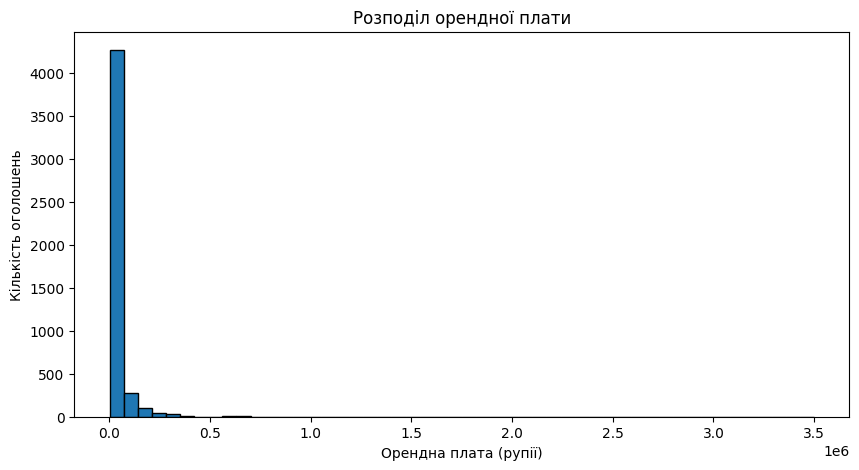

In [8]:

import matplotlib.pyplot as plt

# Будуємо гістограму розподілу орендної плати
plt.figure(figsize=(10, 5))
plt.hist(df['Rent'], bins=50, edgecolor='black')

plt.title('Розподіл орендної плати')
plt.xlabel('Орендна плата (рупії)')
plt.ylabel('Кількість оголошень')
plt.show()



**2.4 Робота з викидами**

Визначимо та видалимо викиди в цільовій змінній Rent за допомогою методу IQR (міжквартильного розмаху).


In [9]:

# Обчислюємо квартилі та міжквартильний розмах
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)
IQR = Q3 - Q1

# Визначаємо межі викидів
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Видаляємо викиди
df_clean = df[(df['Rent'] >= lower) & (df['Rent'] <= upper)].copy()

# Перевіряємо результат
print('Кількість рядків до очищення:', len(df))
print('Кількість видалених викидів:', len(df) - len(df_clean))
print('Кількість рядків після очищення:', len(df_clean))


Кількість рядків до очищення: 4746
Кількість видалених викидів: 520
Кількість рядків після очищення: 4226


**Box plot для змінної Rent**

Побудуємо box plot для цільової змінної Rent, щоб візуально оцінити наявність викидів.

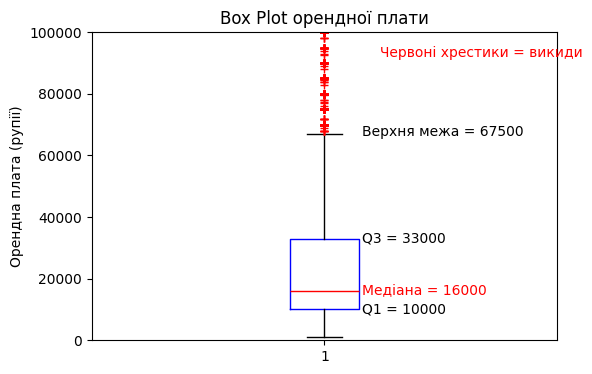

In [10]:
import matplotlib.pyplot as plt

# Дані для box plot
rent = df['Rent']

# Основні статистики
Q1 = rent.quantile(0.25)
median = rent.quantile(0.50)
Q3 = rent.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Найбільший викид
max_outlier = rent.max()

plt.figure(figsize=(6, 4))

plt.boxplot(rent,
            flierprops=dict(marker='+', markeredgecolor='red'),
            boxprops=dict(color='blue'),
            medianprops=dict(color='red'))

plt.title('Box Plot орендної плати')
plt.ylabel('Орендна плата (рупії)')
plt.ylim(0, 100000)

# Підписи до зон
plt.text(1.08, Q1, f'Q1 = {Q1:.0f}', va='center')
plt.text(1.08, median, f'Медіана = {median:.0f}', va='center', color='red')
plt.text(1.08, Q3, f'Q3 = {Q3:.0f}', va='center')
plt.text(1.08, upper, f'Верхня межа = {upper:.0f}', va='center')

# Пояснення для викидів
plt.text(1.12, 92000, 'Червоні хрестики = викиди', color='red')

plt.show()


**2.5 Аналіз категоріальних змінних**

Визначимо кількість унікальних значень у кожному категоріальному стовпці датасету.


In [11]:
# Вибираємо категоріальні стовпці
categorical_cols = df_clean.select_dtypes(include='object')

# Виводимо кількість унікальних значень
print(categorical_cols.nunique())


Posted On              80
Floor                 340
Area Type               3
Area Locality        1997
City                    6
Furnishing Status       3
Tenant Preferred        3
Point of Contact        3
dtype: int64



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


**3.1 Матриця кореляцій**

Обчислимо матрицю кореляцій для числових змінних, щоб визначити силу та напрямок зв'язків між ними.


In [12]:
# Обчислюємо матрицю кореляцій для числових змінних
corr_matrix = df_clean.corr(numeric_only=True)

# Виводимо результат
display(corr_matrix)


,BHK,Rent,Size,Bathroom
BHK,1.000000,0.401268,0.698453,0.747918
Rent,0.401268,1.000000,0.393605,0.506528
Size,0.698453,0.393605,1.000000,0.680607
Bathroom,0.747918,0.506528,0.680607,1.000000


**3.2 Візуалізація кореляційної матриці (Heatmap)**

Побудуємо теплову карту кореляцій, щоб візуально оцінити силу та напрямок зв'язків між числовими змінними.


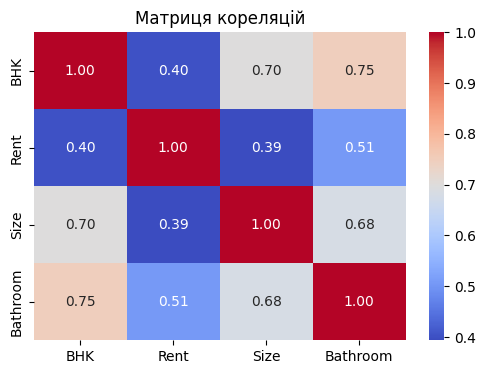

In [13]:

import seaborn as sns
import matplotlib.pyplot as plt

# Будуємо теплову карту кореляційної матриці
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Матриця кореляцій')
plt.show()



**3.3 Діаграма розсіювання (Scatter Plot)**

Побудуємо діаграму розсіювання між площею житла (Size) та орендною платою (Rent), щоб оцінити залежність вартості оренди від площі житла.


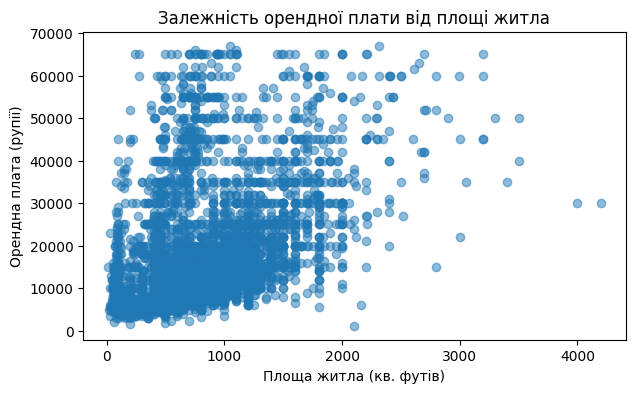

In [14]:
# Будуємо діаграму розсіювання Size та Rent
plt.figure(figsize=(7, 4))
plt.scatter(df_clean['Size'], df_clean['Rent'], alpha=0.5)

plt.title('Залежність орендної плати від площі житла')
plt.xlabel('Площа житла (кв. футів)')
plt.ylabel('Орендна плата (рупії)')
plt.show()



**3.4 Аналіз взаємозв'язку між BHK та Rent (Box Plot)**

Побудуємо Box Plot для порівняння розподілу орендної плати (Rent) залежно від кількості кімнат (BHK).


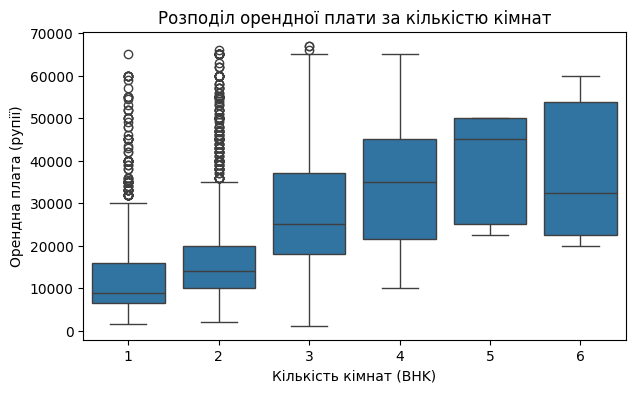

In [15]:
# Будуємо Box Plot для BHK та Rent
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='BHK', y='Rent')

plt.title('Розподіл орендної плати за кількістю кімнат')
plt.xlabel('Кількість кімнат (BHK)')
plt.ylabel('Орендна плата (рупії)')
plt.show()



**Висновок:** Спостерігається позитивний взаємозв'язок між кількістю кімнат (BHK) та орендною платою (Rent). Медіанна вартість оренди загалом зростає зі збільшенням кількості кімнат від 1 до 5. Для 6-кімнатного житла медіана дещо нижча. Значний розкид цін свідчить, що на орендну плату впливають також інші характеристики житла.


## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак



**4.1 Кодування категоріальних змінних (One-Hot Encoding)**

Перетворимо категоріальні змінні з невеликою кількістю унікальних значень на числові за допомогою One-Hot Encoding. Змінні з великою кількістю категорій поки не використовуватимемо.


In [16]:
# Вибираємо категоріальні змінні для кодування
cols = ['City', 'Area Type', 'Furnishing Status', 'Tenant Preferred']

# Виконуємо One-Hot Encoding
df_encoded = pd.get_dummies(df_clean, columns=cols, drop_first=True, dtype=int)

# Перевіряємо результат
print('Розмір датасету:', df_encoded.shape)
display(df_encoded.head())


Розмір датасету: (4226, 19)


,Posted On,BHK,Rent,Size,Floor,Area Locality,Bathroom,Point of Contact,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family
0,2022-05-18,2,10000,1100,Ground out of 2,Bandel,2,Contact Owner,0,0,0,1,0,0,1,0,1,1,0
1,2022-05-13,2,20000,800,1 out of 3,"Phool Bagan, Kankurgachi",1,Contact Owner,0,0,0,1,0,0,1,1,0,1,0
2,2022-05-16,2,17000,1000,1 out of 3,Salt Lake City Sector 2,1,Contact Owner,0,0,0,1,0,0,1,1,0,1,0
3,2022-07-04,2,10000,800,1 out of 2,Dumdum Park,1,Contact Owner,0,0,0,1,0,0,1,0,1,1,0
4,2022-05-09,2,7500,850,1 out of 2,South Dum Dum,1,Contact Owner,0,0,0,1,0,1,0,0,1,0,0



**4.2 Створення нових ознак (Feature Engineering)**

Створимо дві додаткові ознаки на основі наявних даних: площу на одну кімнату (Size_per_BHK) та співвідношення кількості ванних кімнат до кількості кімнат (Bathrooms_per_BHK). Ці показники можуть допомогти моделі врахувати просторість та комфорт житла.


In [17]:
# Обчислюємо площу житла на одну кімнату
df_encoded['Size_per_BHK'] = df_encoded['Size'] / df_encoded['BHK']

# Обчислюємо кількість ванних кімнат на одну кімнату
df_encoded['Bathrooms_per_BHK'] = df_encoded['Bathroom'] / df_encoded['BHK']

# Перевіряємо нові ознаки
display(df_encoded[['BHK', 'Size', 'Bathroom',
                    'Size_per_BHK', 'Bathrooms_per_BHK']].head())


,BHK,Size,Bathroom,Size_per_BHK,Bathrooms_per_BHK
0,2,1100,2,550.0,1.0
1,2,800,1,400.0,0.5
2,2,1000,1,500.0,0.5
3,2,800,1,400.0,0.5
4,2,850,1,425.0,0.5



**4.3 Вибір ознак для побудови моделі**

Виключимо стовпці Posted On, Floor, Area Locality та Point of Contact. Вони містять текстові дані, які не були закодовані, або мають велику кількість унікальних значень. Залишимо числові та закодовані категоріальні ознаки для побудови моделі.


In [18]:
# Видаляємо непотрібні текстові стовпці
df_model = df_encoded.drop(columns=[
    'Posted On', 'Floor', 'Area Locality', 'Point of Contact'
])

# Перевіряємо розмір і типи даних
print('Розмір датасету:', df_model.shape)
print(df_model.dtypes)


Розмір датасету: (4226, 17)
BHK                                    int64
Rent                                   int64
Size                                   int64
Bathroom                               int64
City_Chennai                           int64
City_Delhi                             int64
City_Hyderabad                         int64
City_Kolkata                           int64
City_Mumbai                            int64
Area Type_Carpet Area                  int64
Area Type_Super Area                   int64
Furnishing Status_Semi-Furnished       int64
Furnishing Status_Unfurnished          int64
Tenant Preferred_Bachelors/Family      int64
Tenant Preferred_Family                int64
Size_per_BHK                         float64
Bathrooms_per_BHK                    float64
dtype: object



**4.4 Розділення даних на ознаки (X) та цільову змінну (y)**

Розділимо датасет на незалежні ознаки (X) та цільову змінну (y = Rent) для подальшого навчання моделі.


In [19]:
# Визначаємо незалежні ознаки
X = df_model.drop(columns=['Rent'])

# Визначаємо цільову змінну
y = df_model['Rent']

# Перевіряємо розміри даних
print('Розмір X:', X.shape)
print('Розмір y:', y.shape)


Розмір X: (4226, 16)
Розмір y: (4226,)



**4.5 Стандартизація числових ознак**

Застосуємо StandardScaler для стандартизації числових ознак. Це дозволить привести їх до єдиного масштабу із середнім значенням 0 та стандартним відхиленням 1.


In [20]:
from sklearn.preprocessing import StandardScaler

# Вибираємо числові ознаки для стандартизації
num_cols = ['BHK', 'Size', 'Bathroom', 'Size_per_BHK', 'Bathrooms_per_BHK']

# Створюємо копію даних
X_scaled = X.copy()

# Стандартизуємо числові ознаки
scaler = StandardScaler()
X_scaled[num_cols] = scaler.fit_transform(X[num_cols])

# Перевіряємо результат
display(X_scaled.head())


,BHK,Size,Bathroom,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Size_per_BHK,Bathrooms_per_BHK
0,0.052966,0.469859,0.272578,0,0,0,1,0,0,1,0,1,1,0,0.604132,0.147328
1,0.052966,-0.147778,-1.133910,0,0,0,1,0,0,1,1,0,1,0,-0.268747,-1.637671
2,0.052966,0.263980,-1.133910,0,0,0,1,0,0,1,1,0,1,0,0.313173,-1.637671
3,0.052966,-0.147778,-1.133910,0,0,0,1,0,0,1,0,1,1,0,-0.268747,-1.637671
4,0.052966,-0.044839,-1.133910,0,0,0,1,0,1,0,0,1,0,0,-0.123267,-1.637671


## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.


**5.1 Розділення даних на навчальну та тестову вибірки**

Розділимо дані на навчальну (80%) та тестову (20%) вибірки для подальшого навчання та оцінювання моделі.


In [21]:
from sklearn.model_selection import train_test_split

# Розділяємо дані на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Перевіряємо розміри вибірок
print('Навчальна вибірка:', X_train.shape)
print('Тестова вибірка:', X_test.shape)


Навчальна вибірка: (3380, 16)
Тестова вибірка: (846, 16)



**5.2 Створення моделі лінійної регресії**

Створимо модель LinearRegression для прогнозування орендної плати на основі підготовлених ознак.


In [22]:
from sklearn.linear_model import LinearRegression

# Створюємо модель лінійної регресії
model = LinearRegression()



**5.3 Навчання моделі лінійної регресії**

Навчимо модель лінійної регресії на навчальних даних, використовуючи 16 ознак для прогнозування орендної плати (Rent).


In [23]:
# Навчаємо модель на навчальних даних
model.fit(X_train, y_train)


LinearRegression()


**5.4 Аналіз коефіцієнтів моделі лінійної регресії**

Виведемо всі коефіцієнти моделі та визначимо дві ознаки з найбільшими абсолютними значеннями коефіцієнтів.


In [24]:
# Створюємо таблицю коефіцієнтів моделі
coefficients = pd.Series(model.coef_, index=X_train.columns)

# Сортуємо коефіцієнти за абсолютним значенням
coefficients = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)

# Виводимо всі коефіцієнти
display(coefficients)

# Виводимо дві ознаки з найбільшими коефіцієнтами
print('ТОП-2 ознаки:')
print(coefficients.head(2))


,0
City_Mumbai,22802.841748
Bathrooms_per_BHK,-7265.827777
Bathroom,6751.534212
Furnishing Status_Unfurnished,-4820.648716
City_Delhi,3586.243962
Area Type_Super Area,-3493.929792
Furnishing Status_Semi-Furnished,-3377.752076
City_Kolkata,-3188.360254
City_Hyderabad,-2913.341129
Tenant Preferred_Family,-2718.188932


ТОП-2 ознаки:
City_Mumbai          22802.841748
Bathrooms_per_BHK    -7265.827777
dtype: float64



**5.5 Прогнозування на навчальній та тестовій вибірках**

Зробимо прогнози орендної плати на навчальних і тестових даних за допомогою навченої моделі лінійної регресії.


In [25]:
# Прогнозуємо орендну плату на навчальній вибірці
y_train_pred = model.predict(X_train)

# Прогнозуємо орендну плату на тестовій вибірці
y_test_pred = model.predict(X_test)

# Перевіряємо кількість прогнозів
print('Прогнозів на навчальній вибірці:', len(y_train_pred))
print('Прогнозів на тестовій вибірці:', len(y_test_pred))


Прогнозів на навчальній вибірці: 3380
Прогнозів на тестовій вибірці: 846


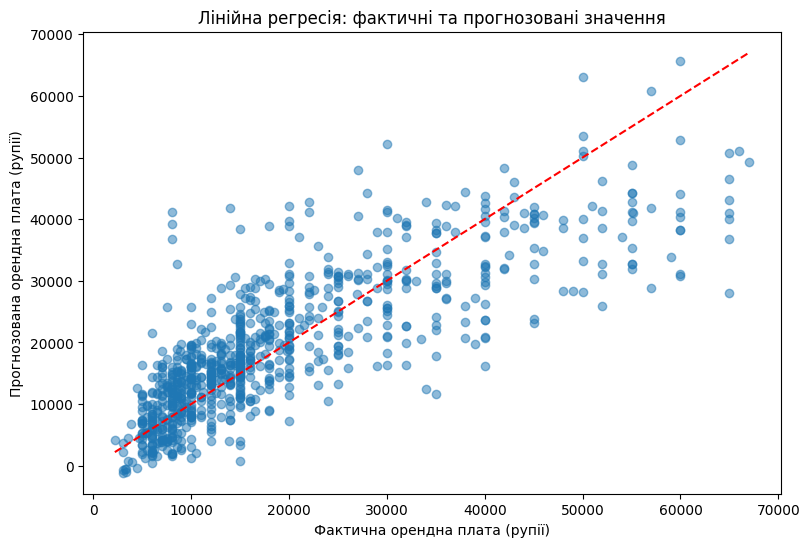

In [26]:
# Порівнюємо фактичні та прогнозовані значення
plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5)

# Лінія ідеального прогнозу
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')

plt.title('Лінійна регресія: фактичні та прогнозовані значення')
plt.xlabel('Фактична орендна плата (рупії)')
plt.ylabel('Прогнозована орендна плата (рупії)')
plt.show()



**Висновок:** Модель лінійної регресії відображає загальну залежність орендної плати від характеристик житла, проте має помітні похибки прогнозування. Спостерігається тенденція до завищення прогнозів для дешевших об'єктів та заниження для дорожчих. Для об'єктивного оцінювання точності моделі необхідно розрахувати метрики MAE, RMSE та R².


## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі



***6.1 Оцінка якості моделі (MAE, RMSE, R²)***

Обчислимо метрики MAE, RMSE та R² для навчальної та тестової вибірок, щоб оцінити точність прогнозування орендної плати та перевірити здатність моделі працювати з новими даними.


In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Обчислюємо метрики для навчальної та тестової вибірок
metrics = pd.DataFrame({
    'MAE': [
        mean_absolute_error(y_train, y_train_pred),
        mean_absolute_error(y_test, y_test_pred)
    ],
    'RMSE': [
        mean_squared_error(y_train, y_train_pred) ** 0.5,
        mean_squared_error(y_test, y_test_pred) ** 0.5
    ],
    'R²': [
        r2_score(y_train, y_train_pred),
        r2_score(y_test, y_test_pred)
    ]
}, index=['Навчальна', 'Тестова'])

# Виводимо результати з округленням до 2 знаків
display(metrics.round(2))


,MAE,RMSE,R²
Навчальна,5933.78,8197.93,0.65
Тестова,5911.48,8173.54,0.65



**6.2 Порівняння метрик та оцінка якості моделі**

**Висновок:** Модель лінійної регресії демонструє помірну якість прогнозування орендної плати (R² = 0.65), пояснюючи близько 65% її варіації.

Середня абсолютна похибка на тестовій вибірці становить 5911,48 рупії, а RMSE — 8173,54 рупії.

Метрики навчальної та тестової вибірок практично однакові, що свідчить про відсутність помітного перенавчання та здатність моделі узагальнювати дані.

**Загальна оцінка:** Модель може використовуватися для орієнтовного прогнозування орендної плати, проте для підвищення точності необхідно покращити набір ознак або випробувати інші алгоритми.



**6.3 Аналіз перенавчання та недонавчання моделі**

**Висновок:** Ознак перенавчання моделі не виявлено, оскільки результати на навчальній та тестовій вибірках практично однакові (R² = 0.65).

Водночас модель пояснює лише 65% варіації орендної плати, що може свідчити про певні ознаки недонавчання або недостатню інформативність вибраних ознак.

**Загальна оцінка:** Модель демонструє стабільну, але помірну якість прогнозування. Для покращення результатів доцільно додати інформативні ознаки або випробувати складніші алгоритми.



**6.4 Порівняння реальних та прогнозованих значень**

Побудуємо графік розсіювання для порівняння фактичної та прогнозованої орендної плати на тестовій вибірці.


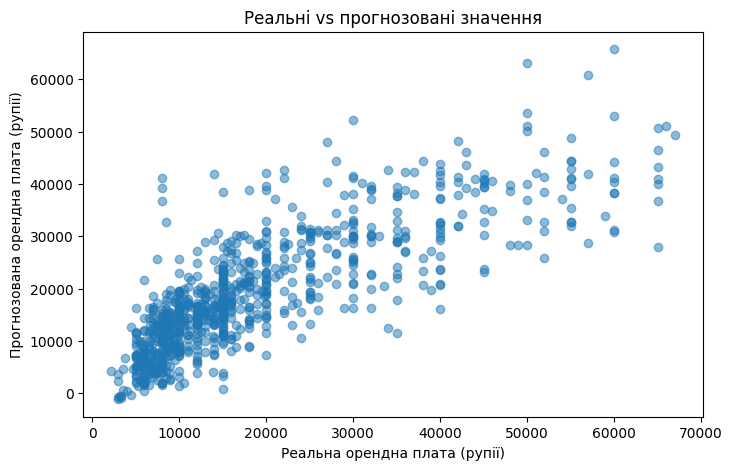

In [28]:

# Будуємо графік реальних та прогнозованих значень
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.title('Реальні vs прогнозовані значення')
plt.xlabel('Реальна орендна плата (рупії)')
plt.ylabel('Прогнозована орендна плата (рупії)')
plt.show()



**Висновок:** Графік демонструє позитивний зв'язок між реальними та прогнозованими значеннями орендної плати. Модель краще прогнозує вартість дешевшого житла, тоді як для дорожчих об'єктів похибки збільшуються і спостерігається тенденція до заниження прогнозів. Показник R² = 0.65 підтверджує помірну якість прогнозування.


## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)


**7.1 Обчислення помилок прогнозування (Residuals)**

Обчислимо помилки прогнозування як різницю між реальними та прогнозованими значеннями орендної плати.


In [29]:

# Обчислюємо помилки прогнозування
residuals = y_test - y_test_pred

# Виводимо перші 5 значень помилок
print(residuals.head())


1998   -8796.484856
3190    2708.650899
2670    -981.575836
4647    5990.073082
4488    -773.513170
Name: Rent, dtype: float64



#### Аналіз результатів прогнозування

Порівняємо помилки прогнозування для перших п'яти записів тестової вибірки.

| Запис | Помилка, рупій | Інтерпретація |
|:---:|---:|:---|
| 1998 | −8 796,48 | Модель завищила прогноз |
| 3190 | +2 708,65 | Модель занизила прогноз |
| 2670 | −981,58 | Модель завищила прогноз |
| 4647 | +5 990,07 | Модель занизила прогноз |
| 4488 | −773,51 | Модель завищила прогноз |

**Інтерпретація помилок:**

- **Додатна (+)** — прогнозована орендна плата нижча за фактичну.
- **Від'ємна (−)** — прогнозована орендна плата вища за фактичну.

**Висновок:** Модель допускає помилки в обох напрямках. Серед наведених п'яти записів найбільша абсолютна помилка становить 8 796,48 рупії (запис 1998).


**7.2 Гістограма розподілу помилок**

Побудуємо гістограму розподілу помилок прогнозування, щоб оцінити, наскільки часто модель помиляється на певну величину та чи є зміщення в один бік.

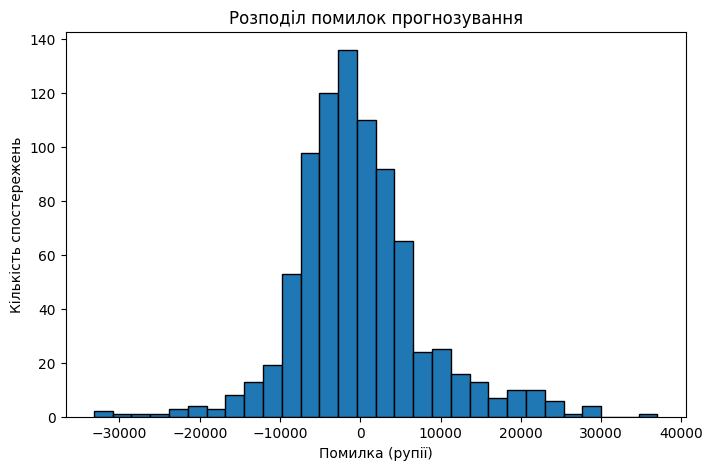

In [30]:
# Будуємо гістограму розподілу помилок
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor='black')

plt.title('Розподіл помилок прогнозування')
plt.xlabel('Помилка (рупії)')
plt.ylabel('Кількість спостережень')
plt.show()


**Висновок:** Розподіл помилок прогнозування приблизно дзвоноподібний, з найбільшою концентрацією значень поблизу нуля. Модель допускає як завищення, так і заниження орендної плати. Наявність значних помилок на краях розподілу свідчить про те, що для окремих об'єктів точність прогнозування залишається недостатньою.



**7.3 Аналіз залежності помилок від прогнозованих значень**

Побудуємо діаграму розсіювання помилок (residuals) відносно прогнозованої орендної плати, щоб перевірити, чи збільшується величина помилок зі зростанням прогнозованих значень.


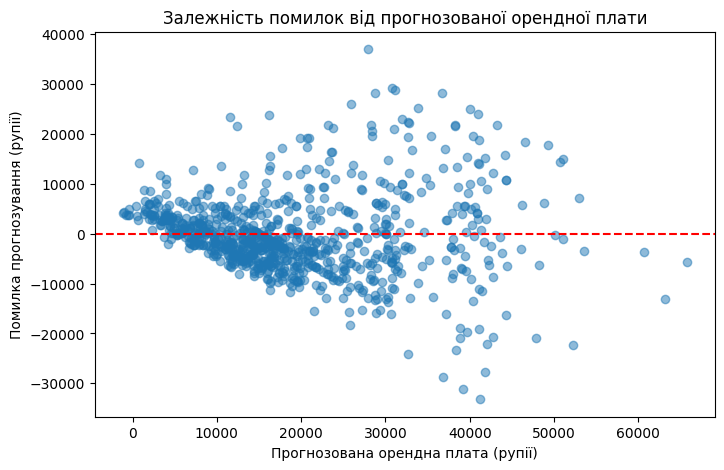

In [31]:

# Будуємо графік помилок відносно прогнозованих значень
plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals, alpha=0.5)

# Додаємо лінію нульової помилки
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Залежність помилок від прогнозованої орендної плати')
plt.xlabel('Прогнозована орендна плата (рупії)')
plt.ylabel('Помилка прогнозування (рупії)')
plt.show()



**Висновок:** Зі збільшенням прогнозованої орендної плати розкид помилок зростає. Для дешевшого житла модель прогнозує точніше, тоді як для дорожчих об'єктів похибки стають більшими.

На графіку спостерігаються ознаки гетероскедастичності — залежності розкиду помилок від прогнозованих значень. Це свідчить про нерівномірну точність моделі для різних цінових категорій житла.



**7.4 Аналіз прогнозів із найбільшими помилками**

Визначимо 5 прогнозів із найбільшими абсолютними помилками та порівняємо фактичні й прогнозовані значення орендної плати.


In [32]:

# Створюємо таблицю фактичних і прогнозованих значень
errors = pd.DataFrame({
    'Реальна плата': y_test,
    'Прогнозована плата': y_test_pred,
    'Помилка': residuals
})

# Обчислюємо абсолютні помилки
errors['Абсолютна помилка'] = errors['Помилка'].abs()

# Виводимо 5 найбільших помилок
display(errors.nlargest(5, 'Абсолютна помилка').round(2))


,Реальна плата,Прогнозована плата,Помилка,Абсолютна помилка
3520,65000,27987.56,37012.44,37012.44
852,8000,41192.74,-33192.74,33192.74
549,8000,39163.42,-31163.42,31163.42
809,60000,30832.29,29167.71,29167.71
2658,60000,31112.25,28887.75,28887.75



**Висновок:** Аналіз п'яти найбільших абсолютних помилок показав значні відхилення прогнозів від фактичної орендної плати (від 28 887,75 до 37 012,44 рупії).

Модель допускає як завищення, так і заниження прогнозів. Це свідчить про недостатню точність для окремих об'єктів житла та необхідність подальшого вдосконалення моделі.



**7.5 Аналіз помилок за типами житла**

Проаналізуємо середню абсолютну помилку прогнозування (MAE) залежно від кількості кімнат (BHK), щоб визначити, для яких типів житла модель помиляється найбільше.


In [33]:

# Додаємо кількість кімнат до таблиці помилок
errors['BHK'] = df_clean.loc[errors.index, 'BHK']

# Обчислюємо середню абсолютну помилку для кожного типу житла
bhk_errors = errors.groupby('BHK')['Абсолютна помилка'].agg(['count', 'mean'])

# Сортуємо за найбільшою середньою помилкою
bhk_errors = bhk_errors.sort_values('mean', ascending=False)

# Виводимо результат
display(bhk_errors.round(2))


,count,mean
BHK,,
5,1,13123.36
4,17,11180.08
3,152,8490.71
6,2,6407.67
2,450,5404.19
1,224,4743.92



**Висновок:** Аналіз показав, що модель найточніше прогнозує орендну плату для житла з 1–2 кімнатами (MAE = 4743,92–5404,19 рупії).

Для житла з 3–4 кімнатами середня абсолютна помилка зростає до 8490,71–11180,08 рупії.

Найбільша помилка спостерігається для 5-кімнатного житла (13123,36 рупії), проте ця група містить лише одне спостереження, тому результат не є репрезентативним.

**Загальний висновок:** Модель краще прогнозує вартість житла з меншою кількістю кімнат. Для великих об'єктів точність прогнозування загалом нижча.



### 7.6 Пропозиції щодо покращення якості моделі

Для підвищення точності прогнозування орендної плати я б запропонував такі кроки:

1. **Додати нові ознаки.** Врахувати поверховість (Floor) та район розташування житла (Area Locality), оскільки вони можуть суттєво впливати на вартість оренди.

2. **Переглянути обробку викидів.** Перевірити, чи всі видалені дорогі об'єкти справді є аномальними, оскільки їх видалення може погіршувати прогнозування високої орендної плати.

3. **Покращити прогнозування дорогого житла.** Дослідити можливість логарифмічного перетворення цільової змінної Rent для зменшення впливу великих значень.

4. **Спробувати інші алгоритми.** Порівняти лінійну регресію з DecisionTreeRegressor, який розглядався на лекції.

5. **Порівняти результати.** Повторно обчислити MAE, RMSE та R² на тестовій вибірці й визначити, чи покращилася якість прогнозування.

**Загальний висновок:** Поточна модель демонструє стабільні результати без помітного перенавчання, проте має обмежену точність для дорогого та багатокімнатного житла. Покращення набору ознак і порівняння різних алгоритмів можуть підвищити якість прогнозування.



**7.6.1 Додавання нових ознак**

Додамо інформацію про поверховість (Floor) та район житла (Area Locality), після чого повторно навчимо лінійну регресію та порівняємо її точність із початковою моделлю.


In [34]:

# Створюємо копію підготовленого датасету
df_new = df_model.copy()

# Перетворюємо інформацію про поверховість на числові ознаки
floor_parts = df_clean['Floor'].str.split(' out of ', n=1, expand=True)

df_new['Floor_Number'] = floor_parts[0].replace({
    'Ground': 0, 'Upper Basement': -1, 'Lower Basement': -2
}).astype(int)

df_new['Total_Floors'] = pd.to_numeric(
    floor_parts[1], errors='coerce'
).fillna(df_new['Floor_Number'].clip(lower=1))

# Вибираємо 20 найпоширеніших районів у навчальній вибірці
top_areas = df_clean.loc[X_train.index, 'Area Locality'].value_counts().head(20).index

# Інші райони об'єднуємо в категорію Other
df_new['Locality'] = df_clean['Area Locality'].where(
    df_clean['Area Locality'].isin(top_areas), 'Other'
)

# Виконуємо One-Hot Encoding для районів
df_new = pd.get_dummies(df_new, columns=['Locality'], drop_first=True, dtype=int)

# Залишаємо ті самі навчальні та тестові записи
X_train_new = df_new.loc[X_train.index].drop(columns='Rent').copy()
X_test_new = df_new.loc[X_test.index].drop(columns='Rent').copy()

# Стандартизуємо числові ознаки
num_cols_new = num_cols + ['Floor_Number', 'Total_Floors']
scaler_new = StandardScaler()

X_train_new[num_cols_new] = scaler_new.fit_transform(X_train_new[num_cols_new])
X_test_new[num_cols_new] = scaler_new.transform(X_test_new[num_cols_new])

# Навчаємо оновлену модель
model_new = LinearRegression()
model_new.fit(X_train_new, y_train)

# Робимо прогнози
y_pred_new = model_new.predict(X_test_new)

# Порівнюємо метрики тестової вибірки
metrics_new = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_new),
    'RMSE': mean_squared_error(y_test, y_pred_new) ** 0.5,
    'R²': r2_score(y_test, y_pred_new)
})

display(pd.DataFrame({
    'Початкова модель': metrics.loc['Тестова'],
    'З новими ознаками': metrics_new
}).T.round(2))


,MAE,RMSE,R²
Початкова модель,5911.48,8173.54,0.65
З новими ознаками,5482.83,7648.94,0.69



**Висновок:** Додавання нових ознак Floor та Area Locality покращило якість прогнозування орендної плати. MAE зменшилася на 7,25%, RMSE — на 6,42%, а R² зріс із 0.65 до 0.69. Отже, інформація про поверховість і розташування житла є корисною для моделі лінійної регресії.



**7.6.2 Перегляд обробки викидів**

Перевіримо вплив видалення викидів на якість прогнозування. Порівняємо два підходи до очищення даних: 1,5 × IQR та 3 × IQR. Збільшення межі дозволить зберегти більше дорогих об'єктів житла.


In [35]:

# Обчислюємо нову верхню межу викидів
upper_new = Q3 + 3 * IQR

# Очищуємо дані за новою межею
df_clean_new = df[(df['Rent'] >= lower) & (df['Rent'] <= upper_new)].copy()

# Порівнюємо результати очищення
print('Початкова кількість записів:', len(df))
print('Після очищення 1.5 × IQR:', len(df_clean))
print('Після очищення 3 × IQR:', len(df_clean_new))
print('Додатково збережено записів:', len(df_clean_new) - len(df_clean))
print('Нова верхня межа:', upper_new)


Початкова кількість записів: 4746
Після очищення 1.5 × IQR: 4226
Після очищення 3 × IQR: 4466
Додатково збережено записів: 240
Нова верхня межа: 102000.0


**Візуалізація перегляду обробки викидів**

Побудуємо box plot орендної плати за правилом 3 × IQR та підпишемо основні статистики: Q1, медіану, Q3 і нову верхню межу викидів.

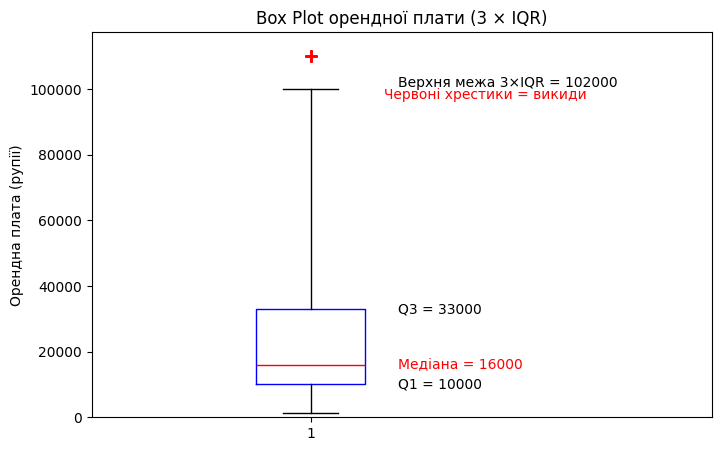

In [36]:
# Обчислюємо основні статистики
Q1 = df['Rent'].quantile(0.25)
median = df['Rent'].median()
Q3 = df['Rent'].quantile(0.75)
IQR = Q3 - Q1

lower_new = Q1 - 3 * IQR
upper_new = Q3 + 3 * IQR

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Box Plot за правилом 3 × IQR
plt.boxplot(
    df['Rent'],
    whis=3,
    flierprops=dict(marker='+', markeredgecolor='red', markersize=8),
    boxprops=dict(color='blue'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='red')
)

plt.title('Box Plot орендної плати (3 × IQR)')
plt.ylabel('Орендна плата (рупії)')

# Залишаємо місце праворуч для підписів
plt.xlim(0.7, 1.55)
plt.ylim(0, upper_new * 1.15)

# Підписи
plt.text(1.12, upper_new, f'Верхня межа 3×IQR = {upper_new:.0f}', va='center')
plt.text(1.12, Q3, f'Q3 = {Q3:.0f}', va='center')
plt.text(1.12, median, f'Медіана = {median:.0f}', color='red', va='center')
plt.text(1.12, Q1, f'Q1 = {Q1:.0f}', va='center')
plt.text(1.10, upper_new * 0.95, 'Червоні хрестики = викиди', color='red')

plt.show()


**Оцінка впливу обробки викидів на якість моделі**

Повторно навчимо модель LinearRegression на розширеній навчальній вибірці після застосування правила 3 × IQR. Порівняємо метрики MAE, RMSE та R² із результатами попередньої моделі.


In [37]:

# Створюємо розширений датасет
df_exp = df_clean_new.copy()

# Додаємо нові числові ознаки
df_exp['Size_per_BHK'] = df_exp['Size'] / df_exp['BHK']
df_exp['Bathrooms_per_BHK'] = df_exp['Bathroom'] / df_exp['BHK']

# Обробляємо інформацію про поверховість
floors = df_exp['Floor'].str.split(' out of ', n=1, expand=True)

df_exp['Floor_Number'] = floors[0].replace({
    'Ground': 0, 'Upper Basement': -1, 'Lower Basement': -2
}).astype(int)

df_exp['Total_Floors'] = pd.to_numeric(
    floors[1], errors='coerce'
).fillna(df_exp['Floor_Number'].clip(lower=1))

# Визначаємо райони за початковою навчальною вибіркою
top_areas = df_clean.loc[X_train.index, 'Area Locality'].value_counts().head(20).index

df_exp['Locality'] = df_exp['Area Locality'].where(
    df_exp['Area Locality'].isin(top_areas), 'Other'
)

# Кодуємо категоріальні змінні
df_exp = pd.get_dummies(
    df_exp,
    columns=['City', 'Area Type', 'Furnishing Status',
             'Tenant Preferred', 'Locality'],
    drop_first=True, dtype=int
)

# Вибираємо ознаки попередньої моделі
features = df_exp.drop(columns=[
    'Rent', 'Posted On', 'Floor', 'Area Locality', 'Point of Contact'
]).reindex(columns=X_train_new.columns, fill_value=0)

# Додаємо повернуті записи до навчальної вибірки
new_idx = df_clean_new.index.difference(df_clean.index)
train_idx = X_train.index.append(new_idx)

X_train_exp = features.loc[train_idx].copy()
X_test_exp = features.loc[X_test.index].copy()
y_train_exp = df_exp.loc[train_idx, 'Rent']

# Стандартизуємо числові ознаки
scaler_exp = StandardScaler()
X_train_exp[num_cols_new] = scaler_exp.fit_transform(X_train_exp[num_cols_new])
X_test_exp[num_cols_new] = scaler_exp.transform(X_test_exp[num_cols_new])

# Навчаємо модель лінійної регресії
model_exp = LinearRegression()
model_exp.fit(X_train_exp, y_train_exp)

# Прогнозуємо орендну плату
y_pred_exp = model_exp.predict(X_test_exp)

# Обчислюємо метрики
metrics_exp = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_exp),
    'RMSE': mean_squared_error(y_test, y_pred_exp) ** 0.5,
    'R²': r2_score(y_test, y_pred_exp)
})

# Порівнюємо результати
comparison_exp = pd.DataFrame({
    '1.5 × IQR + нові ознаки': metrics_new,
    '3 × IQR + нові ознаки': metrics_exp
}).T

display(comparison_exp.round(2))


,MAE,RMSE,R²
1.5 × IQR + нові ознаки,5482.83,7648.94,0.69
3 × IQR + нові ознаки,6825.87,9183.16,0.56



**Висновок:** Збільшення межі викидів із 1,5 × IQR до 3 × IQR дозволило зберегти додаткові 240 записів (4466 замість 4226). Проте повторне навчання моделі показало погіршення якості прогнозування: MAE зросла з 5482,83 до 6825,87 рупії, RMSE — з 7648,94 до 9183,16 рупії, а R² знизився з 0.69 до 0.56.

Отже, збереження додаткових дорогих об'єктів не покращило результати моделі на тестовій вибірці. Для поточної моделі доцільніше використовувати очищення за правилом 1,5 × IQR.



**7.6.3 Логарифмічне перетворення цільової змінної Rent**

Застосуємо логарифмічне перетворення Rent для зменшення впливу високих значень орендної плати. Повторно навчимо модель LinearRegression та порівняємо її точність за метриками MAE, RMSE та R².


In [38]:

import numpy as np

# Логарифмуємо цільову змінну
y_train_log = np.log1p(y_train)

# Навчаємо модель на логарифмованих значеннях
model_log = LinearRegression()
model_log.fit(X_train_new, y_train_log)

# Прогнозуємо та повертаємо значення в рупії
y_pred_log = np.expm1(model_log.predict(X_test_new))

# Обчислюємо метрики
metrics_log = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_log),
    'RMSE': mean_squared_error(y_test, y_pred_log) ** 0.5,
    'R²': r2_score(y_test, y_pred_log)
})

# Порівнюємо результати
comparison_log = pd.DataFrame({
    'Без логарифмування': metrics_new,
    'З логарифмуванням': metrics_log
}).T

display(comparison_log.round(2))


,MAE,RMSE,R²
Без логарифмування,5482.83,7648.94,0.69
З логарифмуванням,5407.27,9059.89,0.57



**Висновок:** Логарифмічне перетворення Rent не забезпечило загального покращення моделі. Незважаючи на незначне зменшення MAE на 1,38%, показник RMSE зріс на 18,45%, а R² знизився з 0.69 до 0.57. Отже, логарифмування дещо зменшило типову абсолютну похибку, але погіршило великі помилки прогнозування. Для подальшого використання доцільно залишити модель без логарифмування.



**7.6.4 Порівняння алгоритмів машинного навчання**

Порівняємо LinearRegression та DecisionTreeRegressor на однакових навчальній і тестовій вибірках із додатковими ознаками Floor та Area Locality. Оцінимо якість моделей за метриками MAE, RMSE та R².


In [39]:
# Імпортуємо алгоритм дерева рішень для регресії
from sklearn.tree import DecisionTreeRegressor

# Створюємо модель дерева рішень із новими ознаками
model_dt_new = DecisionTreeRegressor(max_depth=4, random_state=42)

# Навчаємо модель
model_dt_new.fit(X_train_new, y_train)

# Робимо прогнози
y_pred_dt_new = model_dt_new.predict(X_test_new)

# Обчислюємо метрики
metrics_dt_new = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_dt_new),
    'RMSE': mean_squared_error(y_test, y_pred_dt_new) ** 0.5,
    'R²': r2_score(y_test, y_pred_dt_new)
})

# Порівнюємо результати двох алгоритмів
comparison_alg = pd.DataFrame({
    'LinearRegression': metrics_new,
    'DecisionTreeRegressor': metrics_dt_new
}).T

display(comparison_alg.round(2))


,MAE,RMSE,R²
LinearRegression,5482.83,7648.94,0.69
DecisionTreeRegressor,6353.19,9343.04,0.54



**Висновок:** Порівняння моделей із новими ознаками показало, що LinearRegression забезпечує кращу якість прогнозування, ніж DecisionTreeRegressor. На тестовій вибірці MAE становить 5482,83 проти 6353,19 рупії, RMSE — 7648,94 проти 9343,04 рупії, а R² — 0.69 проти 0.54. Отже, для поточного набору ознак доцільніше використовувати лінійну регресію.




**7.6.5 Порівняння результатів експериментів**

Порівняємо результати всіх експериментів із покращення моделі лінійної регресії: додавання нових ознак, зміни обробки викидів, логарифмування цільової змінної та використання алгоритму DecisionTreeRegressor.

Визначимо найкращу модель за метриками MAE, RMSE та R² на тестовій вибірці.


In [40]:

# Об'єднуємо результати всіх експериментів
final_comparison = pd.DataFrame({
    'Початкова модель': metrics.loc['Тестова'],
    'Нові ознаки': metrics_new,
    '3 × IQR': metrics_exp,
    'Логарифмування Rent': metrics_log,
    'DecisionTreeRegressor': metrics_dt_new
}).T

# Виводимо фінальну таблицю
display(final_comparison.round(2))


,MAE,RMSE,R²
Початкова модель,5911.48,8173.54,0.65
Нові ознаки,5482.83,7648.94,0.69
3 × IQR,6825.87,9183.16,0.56
Логарифмування Rent,5407.27,9059.89,0.57
DecisionTreeRegressor,6353.19,9343.04,0.54



**Висновок:** За результатами п'яти експериментів найкращу загальну якість прогнозування продемонструвала модель LinearRegression із додатковими ознаками Floor та Area Locality (R² = 0.69, RMSE = 7648,94 рупії).

Логарифмування Rent забезпечило найменшу MAE (5407,27 рупії), проте погіршило інші метрики. Збільшення межі викидів до 3 × IQR та використання DecisionTreeRegressor також не покращили загальну якість прогнозування.

**Для подальшого використання обрано LinearRegression із новими ознаками та очищенням даних за правилом 1,5 × IQR.**


**7.6.6 Візуальне порівняння результатів експериментів**

Побудуємо графіки для наочного порівняння п’яти експериментів за метриками MAE, RMSE та R². Це дозволить візуально визначити модель, яка забезпечує найкращу якість прогнозування.


* Графік MAE


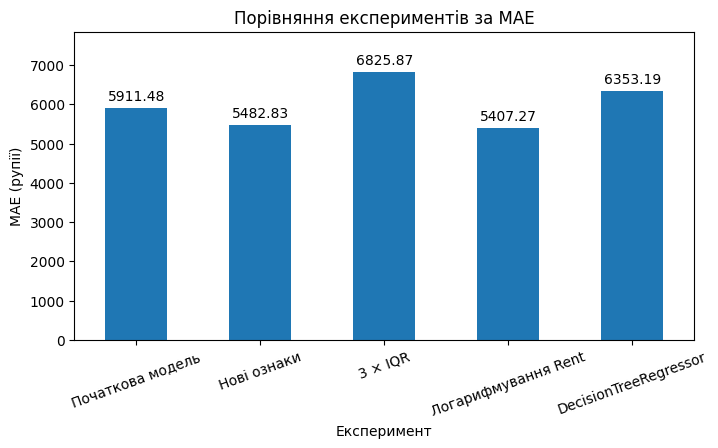

In [41]:
# Графік MAE
ax = final_comparison['MAE'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за MAE')
plt.xlabel('Експеримент')
plt.ylabel('MAE (рупії)')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['MAE'].max() * 1.15)
plt.show()



**Висновок:** Найменшу середню абсолютну помилку (MAE = 5012,18 рупії) отримано для моделі RandomForestRegressor (Випадковий ліс). Це на 15,21% менше порівняно з початковою моделлю (5911,48 рупії) та на 8,58% менше порівняно з LinearRegression із новими ознаками (5482,83 рупії). Отже, RandomForestRegressor забезпечує найточніше прогнозування орендної плати серед шести експериментів за метрикою MAE.



* Графік RMSE

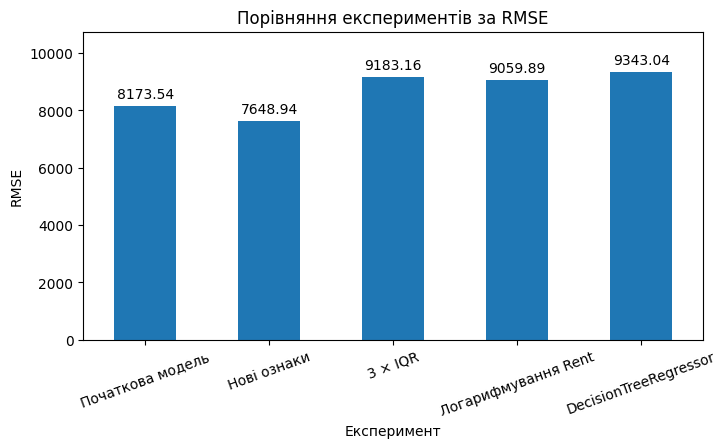

In [42]:
# Графік RMSE
ax = final_comparison['RMSE'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за RMSE')
plt.xlabel('Експеримент')
plt.ylabel('RMSE')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['RMSE'].max() * 1.15)
plt.show()


**Висновок:** Найменше значення RMSE = 7648,94 рупії отримано для моделі LinearRegression із новими ознаками Floor та Area Locality, що на 6,42% менше порівняно з початковою моделлю (8173,54 рупії). Інші експерименти показали вищі значення RMSE, тому додавання нових ознак виявилося найефективнішим способом зменшення квадратичної похибки прогнозування.


* Графік R²

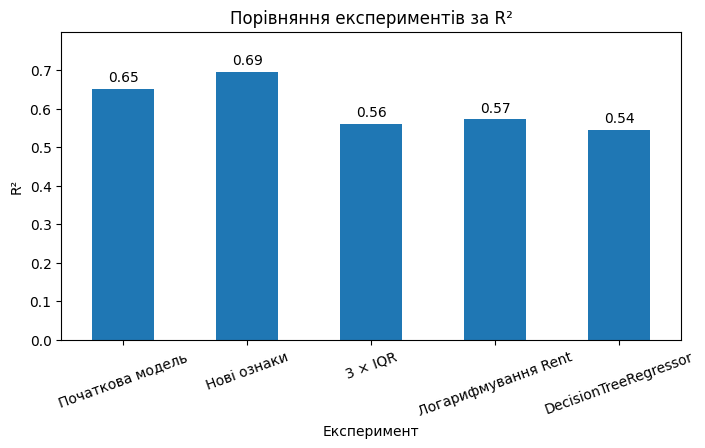

In [43]:
# Графік R²
ax = final_comparison['R²'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за R²')
plt.xlabel('Експеримент')
plt.ylabel('R²')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['R²'].max() * 1.15)
plt.show()


**Висновок:** Найвищий показник R² = 0.69 отримано для моделі LinearRegression із новими ознаками Floor та Area Locality, що на 0.04 більше порівняно з початковою моделлю (R² = 0.65). Інші експерименти показали нижчі результати (R² від 0.54 до 0.57). Отже, додавання нових ознак виявилося найефективнішим підходом для підвищення пояснювальної здатності моделі на тестовій вибірці.



**Загальний висновок:** Візуальне порівняння п'яти експериментів за метриками MAE, RMSE та R² показало, що найкращу загальну якість прогнозування забезпечує модель LinearRegression із додатковими ознаками Floor та Area Locality.

Порівняно з початковою моделлю MAE зменшилася на 7,25%, RMSE — на 6,42%, а R² зріс із 0.65 до 0.69. Хоча логарифмування Rent забезпечило найменшу MAE (5407,27 рупії), воно суттєво погіршило RMSE та R².

**Найефективнішою серед перевірених моделей є LinearRegression із новими ознаками та очищенням даних за правилом 1,5 × IQR.**



**7.6.7 Порівняння моделей із RandomForestRegressor(Випадковий ліс)**

Додамо третій алгоритм RandomForestRegressor (Випадковий ліс) для прогнозування орендної плати. Навчимо модель на тих самих даних із новими ознаками та порівняємо результати з LinearRegression і DecisionTreeRegressor за метриками MAE, RMSE та R².


In [45]:
# Імпортуємо алгоритм випадкового лісу для регресії
from sklearn.ensemble import RandomForestRegressor

# Створюємо модель випадкового лісу
model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42
)

# Навчаємо модель
model_rf.fit(X_train_new, y_train)

# Робимо прогнози
y_pred_rf = model_rf.predict(X_test_new)

# Обчислюємо метрики
metrics_rf = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_rf),
    'RMSE': mean_squared_error(y_test, y_pred_rf) ** 0.5,
    'R²': r2_score(y_test, y_pred_rf)
})

# Порівнюємо три алгоритми
comparison_alg = pd.DataFrame({
    'LinearRegression': metrics_new,
    'DecisionTreeRegressor': metrics_dt_new,
    'RandomForestRegressor': metrics_rf
}).T

display(comparison_alg.round(2))


,MAE,RMSE,R²
LinearRegression,5482.83,7648.94,0.69
DecisionTreeRegressor,6353.19,9343.04,0.54
RandomForestRegressor,5012.18,7522.47,0.70



**Висновок:** Порівняння трьох алгоритмів показало, що найкращу якість прогнозування орендної плати забезпечує RandomForestRegressor (Випадковий ліс).

Модель має найменші похибки MAE = 5012,18 рупії та RMSE = 7522,47 рупії, а також найвищий показник R² = 0.70.

Отже, використання RandomForestRegressor дозволило покращити результати порівняно з LinearRegression та DecisionTreeRegressor. Серед трьох перевірених алгоритмів випадковий ліс є найефективнішим на поточній тестовій вибірці.


In [46]:
# Додаємо результати RandomForestRegressor
final_comparison.loc['RandomForestRegressor'] = metrics_rf

# Виводимо оновлену таблицю
display(final_comparison.round(2))


,MAE,RMSE,R²
Початкова модель,5911.48,8173.54,0.65
Нові ознаки,5482.83,7648.94,0.69
3 × IQR,6825.87,9183.16,0.56
Логарифмування Rent,5407.27,9059.89,0.57
DecisionTreeRegressor,6353.19,9343.04,0.54
RandomForestRegressor,5012.18,7522.47,0.70


* Графік MAE (RandomForestRegressor)

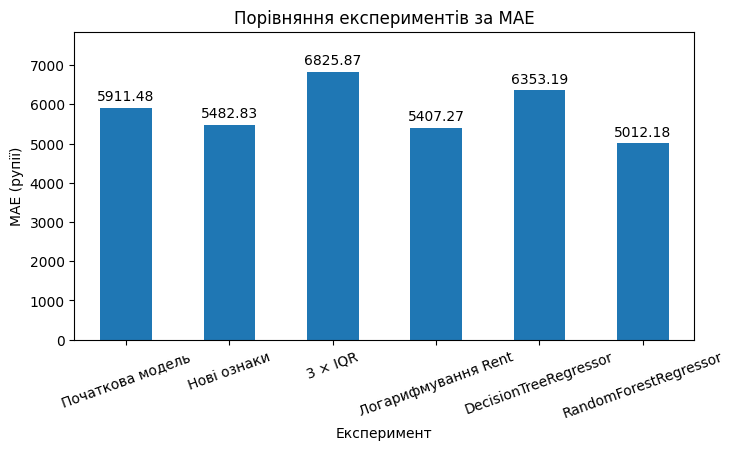

In [47]:

# Графік MAE
ax = final_comparison['MAE'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за MAE')
plt.xlabel('Експеримент')
plt.ylabel('MAE (рупії)')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['MAE'].max() * 1.15)
plt.show()



**Висновок:** Найменшу середню абсолютну помилку (MAE = 5012,18 рупії) отримано для моделі RandomForestRegressor (Випадковий ліс). Це на 15,21% менше порівняно з початковою моделлю (5911,48 рупії) та на 8,58% менше порівняно з LinearRegression із новими ознаками (5482,83 рупії). Отже, RandomForestRegressor забезпечує найточніше прогнозування орендної плати серед шести експериментів за показником MAE.


* * Графік RMSE (RandomForestRegressor)

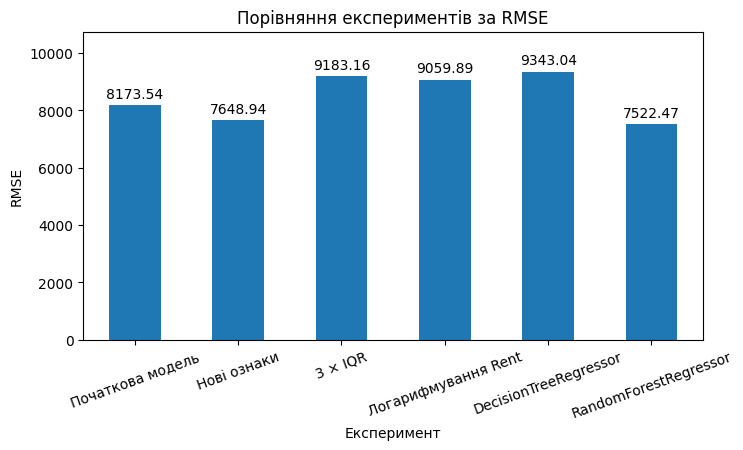

In [48]:
# Графік RMSE
ax = final_comparison['RMSE'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за RMSE')
plt.xlabel('Експеримент')
plt.ylabel('RMSE')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['RMSE'].max() * 1.15)
plt.show()


**Висновок:** Найменше значення RMSE = 7522,47 рупії отримано для моделі RandomForestRegressor (Випадковий ліс), що на 1,65% менше порівняно з LinearRegression із новими ознаками (7648,94 рупії) та на 7,97% менше за початкову модель (8173,54 рупії). Отже, RandomForestRegressor забезпечує найкращу якість прогнозування серед шести експериментів за метрикою RMSE.


* Графік R² (RandomForestRegressor)

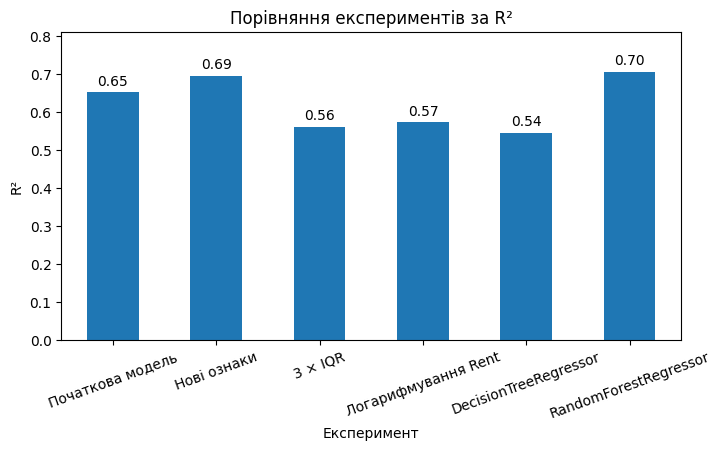

In [49]:
# Графік R²
ax = final_comparison['R²'].plot(kind='bar', figsize=(8, 4))

plt.title('Порівняння експериментів за R²')
plt.xlabel('Експеримент')
plt.ylabel('R²')
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.ylim(0, final_comparison['R²'].max() * 1.15)
plt.show()


**Висновок:** Найвищий показник R² = 0.70 отримано для моделі RandomForestRegressor (Випадковий ліс), що на 0.01 більше порівняно з LinearRegression із новими ознаками (R² = 0.69) та на 0.05 більше за початкову модель (R² = 0.65). Отже, RandomForestRegressor продемонстрував найкращу пояснювальну здатність серед шести перевірених експериментів.



**Порівняння фактичних і прогнозованих значень трьох моделей**

Побудуємо окремі діаграми розсіювання для LinearRegression, DecisionTreeRegressor та RandomForestRegressor, щоб наочно порівняти точність прогнозування орендної плати на тестовій вибірці.



**Порівняння фактичної та прогнозованої орендної плати за трьома моделями машинного навчання**

Побудуємо три діаграми розсіювання для моделей лінійної регресії (LinearRegression), дерева рішень (DecisionTreeRegressor) та випадковий ліс (RandomForestRegressor).Порівняємо прогнозовані значення з фактичною орендною платою на тестовій вибірці, щоб візуально оцінити точність кожної моделі та визначити найефективніший алгоритм.


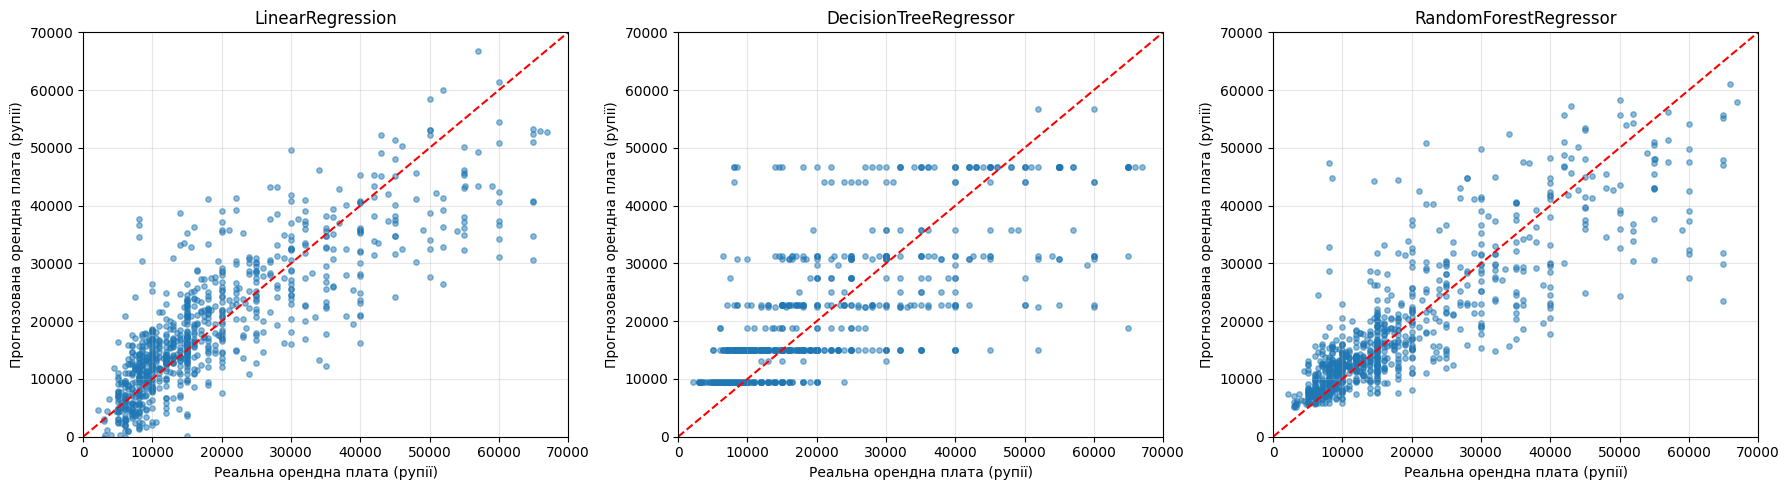

In [50]:

# Створюємо три графіки в одному рядку
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Назви моделей та їхні прогнози
models = [
    ('LinearRegression', y_pred_new),
    ('DecisionTreeRegressor', y_pred_dt_new),
    ('RandomForestRegressor', y_pred_rf)
]

# Будуємо графік для кожної моделі
for ax, (name, pred) in zip(axes, models):
    ax.scatter(y_test, pred, alpha=0.5, s=15)
    ax.plot([0, 70000], [0, 70000], 'r--')

    ax.set_title(name)
    ax.set_xlabel('Реальна орендна плата (рупії)')
    ax.set_ylabel('Прогнозована орендна плата (рупії)')
    ax.set_xlim(0, 70000)
    ax.set_ylim(0, 70000)
    ax.grid(alpha=0.3)

# Налаштовуємо відстань між графіками
plt.tight_layout()
plt.show()



**Висновок:** Візуальне порівняння трьох моделей показало, що LinearRegression та RandomForestRegressor мають схожий розподіл прогнозованих значень відносно лінії ідеального прогнозу, тоді як DecisionTreeRegressor демонструє менш рівномірне наближення до лінії ідеального прогнозу та характерні горизонтальні смуги.За числовими метриками RandomForestRegressor забезпечує дещо кращу якість прогнозування: MAE зменшилася на 8,58%, RMSE  на 1,65%, а R² зріс із 0,69 до 0,70 порівняно з LinearRegression.
**Найкращу якість прогнозування орендної плати серед трьох перевірених моделей машинного навчання продемонструвала модель RandomForestRegressor, побудована на основі алгоритму "випадковий ліс".** Водночас її перевага над моделлю лінійної регресії за метриками RMSE та R² є незначною.




**Додатковий експеримент — DecisionTreeRegressor**

Навчимо модель дерева рішень та порівняємо її точність із лінійною регресією. Обмежимо глибину дерева для зменшення ризику перенавчання.


In [51]:

from sklearn.tree import DecisionTreeRegressor

# Створюємо модель дерева рішень
model_dt = DecisionTreeRegressor(max_depth=4, random_state=42)

# Навчаємо модель
model_dt.fit(X_train, y_train)

# Прогнозуємо на навчальній та тестовій вибірках
y_train_pred_dt = model_dt.predict(X_train)
y_test_pred_dt = model_dt.predict(X_test)

# Перевіряємо кількість прогнозів
print('Навчальна вибірка:', len(y_train_pred_dt))
print('Тестова вибірка:', len(y_test_pred_dt))


Навчальна вибірка: 3380
Тестова вибірка: 846



 **Порівняння двох моделей**

Обчислимо метрики MAE, RMSE та R² для моделі дерева рішень (DecisionTreeRegressor) і порівняємо їх із результатами лінійної регресії (LinearRegression).


In [52]:

# Обчислюємо метрики дерева рішень
metrics_dt = pd.DataFrame({
    'MAE': [
        mean_absolute_error(y_train, y_train_pred_dt),
        mean_absolute_error(y_test, y_test_pred_dt)
    ],
    'RMSE': [
        mean_squared_error(y_train, y_train_pred_dt) ** 0.5,
        mean_squared_error(y_test, y_test_pred_dt) ** 0.5
    ],
    'R²': [
        r2_score(y_train, y_train_pred_dt),
        r2_score(y_test, y_test_pred_dt)
    ]
}, index=['Навчальна', 'Тестова'])

# Порівнюємо метрики двох моделей
comparison = pd.concat({
    'LinearRegression': metrics,
    'DecisionTreeRegressor': metrics_dt
})

display(comparison.round(2))


MAE     RMSE    R²
LinearRegression      Навчальна  5933.78  8197.93  0.65
                      Тестова    5911.48  8173.54  0.65
DecisionTreeRegressor Навчальна  5686.86  8029.53  0.66
                      Тестова    6045.03  8739.38  0.60


**Висновок:** Порівняння двох моделей показало, що LinearRegression забезпечує кращу якість прогнозування на тестовій вибірці (R² = 0.65, MAE = 5911,48 рупії).

DecisionTreeRegressor має дещо кращі результати на навчальній вибірці, проте на тестовій його точність знижується (R² = 0.60), що свідчить про певні ознаки перенавчання.

**Загальний висновок:** Для поточного набору даних LinearRegression є кращою моделлю. Використання дерева рішень із максимальною глибиною 4 не покращило якість прогнозування.


**Візуальне порівняння моделей**

Побудуємо графіки для порівняння якості моделей LinearRegression та DecisionTreeRegressor на тестовій вибірці.

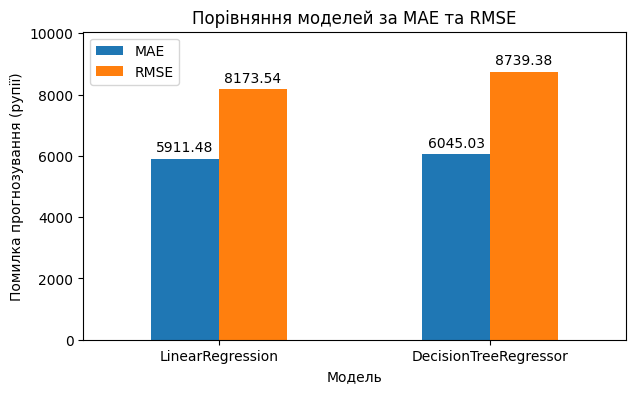

In [53]:
# Беремо розраховані метрики тестової вибірки
comparison_test = comparison.xs('Тестова', level=1)[['MAE', 'RMSE']]

# Будуємо графік порівняння моделей
ax = comparison_test.plot(kind='bar', figsize=(7, 4))

plt.title('Порівняння моделей за MAE та RMSE')
plt.xlabel('Модель')
plt.ylabel('Помилка прогнозування (рупії)')
plt.xticks(rotation=0)

# Додаємо значення над стовпчиками
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

# Збільшуємо верхню межу осі Y на 15% для підписів
plt.ylim(0, comparison_test.max().max() * 1.15)


plt.show()



**Висновок:** Модель LinearRegression демонструє кращу точність прогнозування орендної плати порівняно з DecisionTreeRegressor, оскільки має нижчі значення MAE (5911,48 проти 6045,03 рупії) та RMSE (8173,54 проти 8739,38 рупії) на тестовій вибірці.


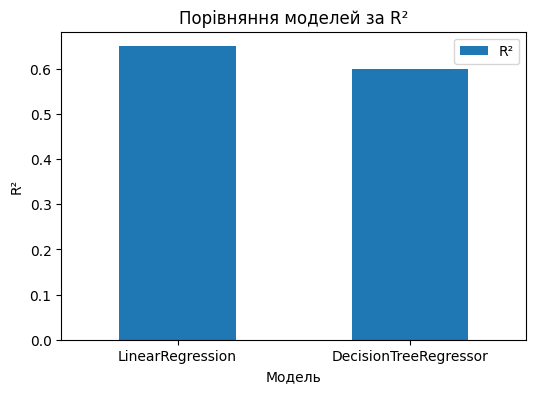

In [54]:
# Таблиця для R²
comparison_r2 = pd.DataFrame({
    'R²': [0.65, 0.60]
}, index=['LinearRegression', 'DecisionTreeRegressor'])

# Будуємо графік
comparison_r2.plot(kind='bar', figsize=(6, 4))

plt.title('Порівняння моделей за R²')
plt.xlabel('Модель')
plt.ylabel('R²')
plt.xticks(rotation=0)
plt.show()

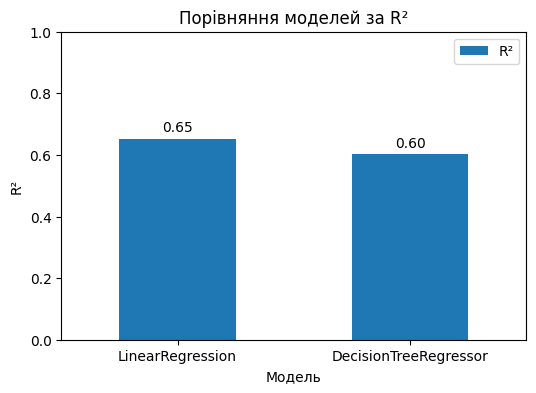

In [55]:

# Беремо розраховані значення R² тестової вибірки
comparison_r2 = comparison.xs('Тестова', level=1)[['R²']]

# Будуємо графік
ax = comparison_r2.plot(kind='bar', figsize=(6, 4))

plt.title('Порівняння моделей за R²')
plt.xlabel('Модель')
plt.ylabel('R²')
plt.xticks(rotation=0)

# Додаємо значення над стовпчиками
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

# Залишаємо місце для підписів
plt.ylim(0, 1)

plt.show()


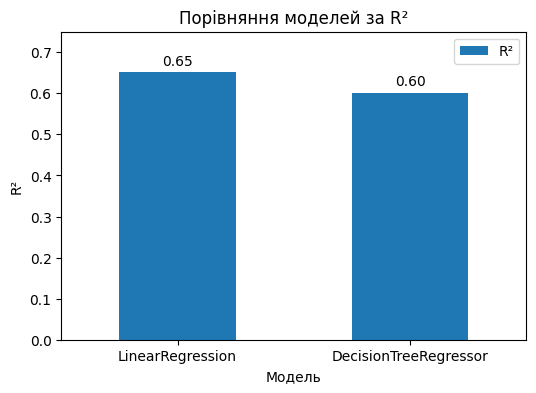

In [56]:

# Таблиця з метриками R²
comparison_r2 = comparison.xs('Тестова', level=1)[['R²']]

# Будуємо графік
ax = comparison_r2.plot(kind='bar', figsize=(6, 4))

plt.title('Порівняння моделей за R²')
plt.xlabel('Модель')
plt.ylabel('R²')
plt.xticks(rotation=0)

# Додаємо значення над стовпчиками
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)
    # Збільшуємо верхню межу осі Y для підписів
plt.ylim(0, 0.75)

plt.show()



**Висновок:** Модель LinearRegression демонструє кращу якість прогнозування орендної плати (R² = 0.65), ніж DecisionTreeRegressor (R² = 0.60). Це означає, що лінійна регресія пояснює приблизно 65% варіації орендної плати проти 60% у дерева рішень, тому є ефективнішою для поточного набору даних.
